## Module 3: Computational Drug Discovery Project 



## Project Goal:

You are working as a Quantitative Systems Pharmacologist at the UVA Manning Institute for Biotechnology. Your overall goal is to help develop a GLP1 agonist drug for weight loss, branded Cavalitide, that will compete with semaglutide (Ozempic or Wegovy). Your project is composed of three tasks:
* Task 1: Fit a receptor binding (pharmacodynamics) model for Cavalitide
* Task 2: Simulate the pharmacokinetics of Cavalitide treatment
* Task 3: Simulate a combined pharmacokinetics-pharmacodynamics (PKPD) model that predicts GLP1 receptor activity during treatment.
  
The below sections should be addressed in your Project Report as a Jupyter notebook, based on Module3_Project_Template.ipynb. All groups submit a Project Report, only those in the Sullivan Company have Oral Presentations (**all due 11/17**).

## Disease Background: 
Provide a brief (<200 word) background of obesity, available treatments, and especially why improved treatments are needed. Your answers may include for example: 
Prevalence & incidence, Symptoms, Diagnosis, Standard of care treatments (& reimbursement), Disease progression & prognosis, Biological mechanisms (anatomy, organ physiology, cell & molecular physiology), Clinical Trials/next-gen therapies.

Please provide citations and/or hyperlinks to where you obtained information (including AI) for each of the bullet points.

## Task 1: Fit a receptor binding model for Cavalitide:

Your colleague in Lead Discovery has identified a small molecule, Cavalitide, and performed experiments testing its binding to the GLP1 receptor (below, and available as cavalitide_data.csv). You now aim to develop a pharmacodynamics model of how GLP1 and Cavalitide can each bind and activate the GLP1 receptor. 
a)	Adapt your previous codes for modeling semaglutide (fit_semaglutide.py, semaglutide_data.csv) to fit the Cavalitide binding data. 
b)	Show a plot of [Cavalitide] vs. Fraction active receptors (Fact) demonstrating a good fit.
c)	Provide the fitted value of Kd for Cavalitide. Interpret the Kd of Cavalitide versus that of semaglutide, commenting on advantages/disadvantages.

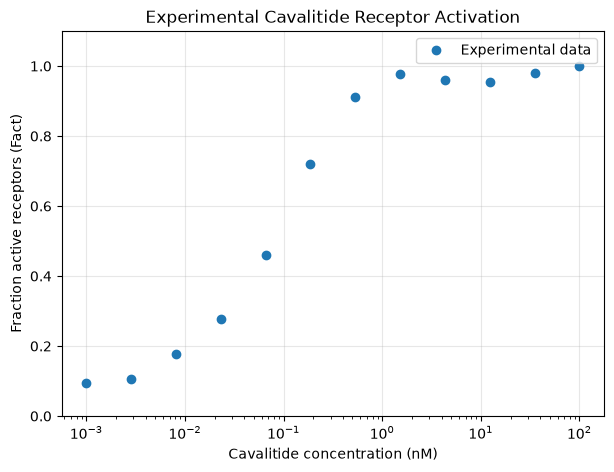

In [1]:

import numpy as np
import matplotlib.pyplot as plt

#experimental Cavalitide data
data = np.loadtxt("cavalitide_data.csv", delimiter=",", skiprows=1)

#separates the cavalitide concentration and the fraction of active receptors into two different arrays
cavalitide = data[:, 0]
Fact_data = data[:, 1]

#plot the experimental data
plt.figure(figsize=(7, 5))
plt.semilogx(cavalitide, Fact_data, "o", label="Experimental data")

plt.xlabel("Cavalitide concentration (nM)")
plt.ylabel("Fraction active receptors (Fact)")
plt.title("Experimental Cavalitide Receptor Activation")
plt.ylim(0, 1.1)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


Fitted Cavalitide Kd = 0.0770 nM
SSE = 0.005154
R-squared = 0.9968


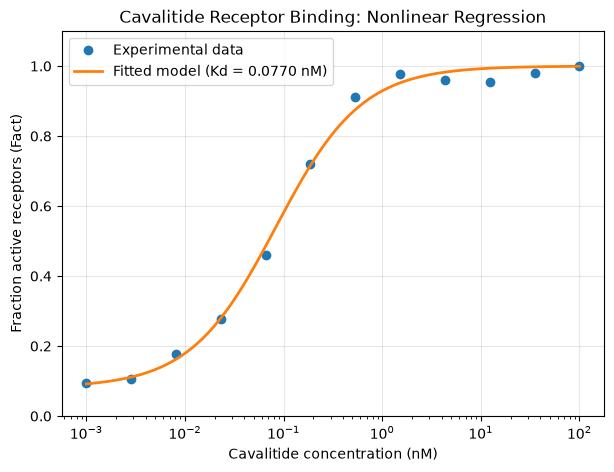

In [ ]:

from scipy.optimize import curve_fit

#the dissociation constant & concentration of the natural GLP1
Kd_GLP1 = 0.17
GLP1_fasting = 0.015

#receptor activation model with two ligands that are competing for the same receptor
def Fact(GLP1, Cavalitide, Kd1, Kd2):
    return (Kd2*GLP1 + Kd1*Cavalitide) / (Kd1*Kd2 + Kd2*GLP1 + Kd1*Cavalitide)

#Hold GLP1 constant and fit Cavalitide's Kd
def model(Cavalitide, Kd_Cavalitide):
    return Fact(GLP1_fasting, Cavalitide, Kd_GLP1, Kd_Cavalitide)

#Find the best-fitting Kd using nonlinear regression
popt, pcov = curve_fit(
    model, cavalitide, Fact_data,
    p0=[0.1], bounds=(0.000001, np.inf)
)

Kd_Cavalitide = popt[0]

#Calculate model predictions and fitting accuracy
predicted = model(cavalitide, Kd_Cavalitide)

SSE = np.sum((Fact_data - predicted)**2)
SST = np.sum((Fact_data - np.mean(Fact_data))**2)
R2 = 1 - SSE/SST

print(f"Fitted Cavalitide Kd = {Kd_Cavalitide:.4f} nM")
print(f"SSE = {SSE:.6f}")
print(f"R-squared = {R2:.4f}")

#Plot experimental data and fitted curve
Cavalitide_range = np.logspace(-3, 2, 500)

plt.figure(figsize=(7, 5))
plt.semilogx(cavalitide, Fact_data, "o", label="Experimental data")
plt.semilogx(
    Cavalitide_range,
    model(Cavalitide_range, Kd_Cavalitide),
    "-", linewidth=2,
    label=f"Fitted model (Kd = {Kd_Cavalitide:.4f} nM)"
)

plt.xlabel("Cavalitide concentration (nM)")
plt.ylabel("Fraction active receptors (Fact)")
plt.title("Cavalitide Receptor Binding: Nonlinear Regression")
plt.ylim(0, 1.1)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


Cavalitide Kd = 0.0770 nM
Semaglutide Kd = 0.3498 nM
Affinity ratio = 4.54x


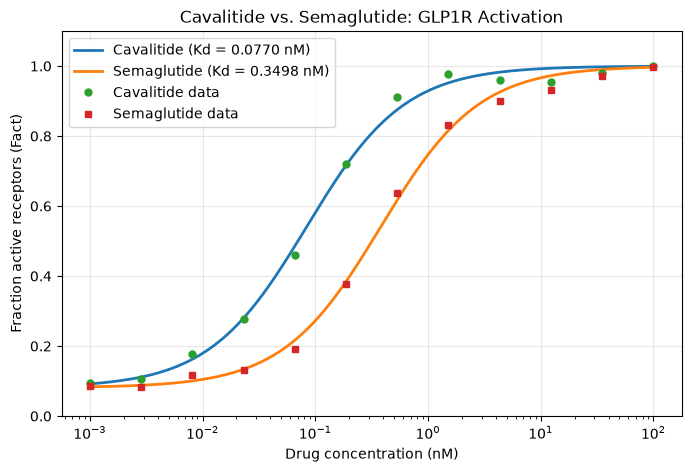

In [3]:

# Load semaglutide experimental data
sema_data = np.loadtxt("semaglutide_data.csv",
                       delimiter=",", skiprows=1)

sema_conc = sema_data[:, 0]
sema_Fact = sema_data[:, 1]

#Fit semaglutide using the same receptor-binding model
popt_sema, pcov_sema = curve_fit(
    model, sema_conc, sema_Fact,
    p0=[0.38], bounds=(0.000001, np.inf)
)

Kd_sema = popt_sema[0]

#Compare the two binding affinities
affinity_ratio = Kd_sema / Kd_Cavalitide

print(f"Cavalitide Kd = {Kd_Cavalitide:.4f} nM")
print(f"Semaglutide Kd = {Kd_sema:.4f} nM")
print(f"Affinity ratio = {affinity_ratio:.2f}x")

#Generate fitted curves
concentrations = np.logspace(-3, 2, 500)

plt.figure(figsize=(8, 5))

plt.semilogx(
    concentrations,
    model(concentrations, Kd_Cavalitide),
    label=f"Cavalitide (Kd = {Kd_Cavalitide:.4f} nM)",
    linewidth=2
)

plt.semilogx(
    concentrations,
    model(concentrations, Kd_sema),
    label=f"Semaglutide (Kd = {Kd_sema:.4f} nM)",
    linewidth=2
)

plt.semilogx(cavalitide, Fact_data, "o",
             label="Cavalitide data", markersize=5)

plt.semilogx(sema_conc, sema_Fact, "s",
             label="Semaglutide data", markersize=5)

plt.xlabel("Drug concentration (nM)")
plt.ylabel("Fraction active receptors (Fact)")
plt.title("Cavalitide vs. Semaglutide: GLP1R Activation")
plt.ylim(0, 1.1)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


Task 1 :  Results & Interpretation


## Task 2: Simulate the pharmacokinetics of Cavalitide treatment

TBD

## Task 3: Simulate a combined pharmacokinetics-pharmacokinetics (PKPD) model that predicts GLP1 receptor activity during treatment

TBD

## Conclusions:

Explain what your analyses suggest about the potential for Cavalitide in competition with semaglutide (oral or injected).

## Limitations and Future Work:

Describe the limitations of your project. If you had more time or additional data, explain how you would improve the analysis.

## AI Usage Statement:
*This is where you will provide a short description on whether AI (and which AI) was used for any of the sections above and whether it helped or why it did not help.*
- *Example statement: "We used Claude Code to generate our linear regression plot. At first, it did not include an R^2 calculation, so we added it to the code afterwards."*

## GitHub Repository Link:
*Please provide the link to your shared GitHub repository that includes this notebook and any other scripts, notebooks, or data that you used for this project.*


## References:
*You can use any format you like but provide the citations for facts that you referenced in this project notebook.*

## NOTES FROM YOUR TEAM: 
*This is where our team is taking notes and recording activity.*

## QUESTIONS FOR YOUR TA: 
*These are questions we have for our TA.*